# code_191 · Validity and accuracy need separate structure-aware scores

**Book:** section 36.4. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_36_GUIDE.md), [execution evidence](../CHAPTER_36_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_191).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Evaluation contracts identify the population, sampling unit, available information, score direction and decision consequences. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=7791;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 7791


<a id="node-edge-and-field-validity"></a>
 ## Score a field at the sampling resolution and physical boundary
 Generate 80 source and 40 independent final path graphs, 24 nodes on [0,1], with a load q per graph and exact field u=q x(1−x) mm. It solves −u″=2q and has zero endpoint displacement. Source observations at interior nodes contain independent noise. Fit an unconstrained polynomial ridge on q,x,x²,qx,qx², and a scalar least-squares coefficient multiplying the boundary-conforming basis qx(1−x). Neither final field enters fitting. Score nodal RMSE, finite-difference edge-gradient RMSE, per-graph peak error, trapezoidal spatial L2 error, maximum support displacement and interior equation residual. Decompose interior residuals with the normalized type-I discrete sine transform; the transform is a diagnostic coordinate system, not a substitute for reporting violated endpoints. The generated equation and exact field are available here; a field dataset may lack this audit privilege.


,node_RMSE_mm,edge_gradient_RMSE_mm_per_length,graph_peak_MAE_mm,mean_field_L2_mm,maximum_boundary_mm,equation_residual_RMS,high_mode_residual_energy
Polynomial ridge,0.018685,0.132209,0.014892,0.014098,0.089077,0.458208,1.698451e-04
Conforming basis,0.001027,0.003315,0.001369,0.001002,0.000000,0.011495,7.441000e-12


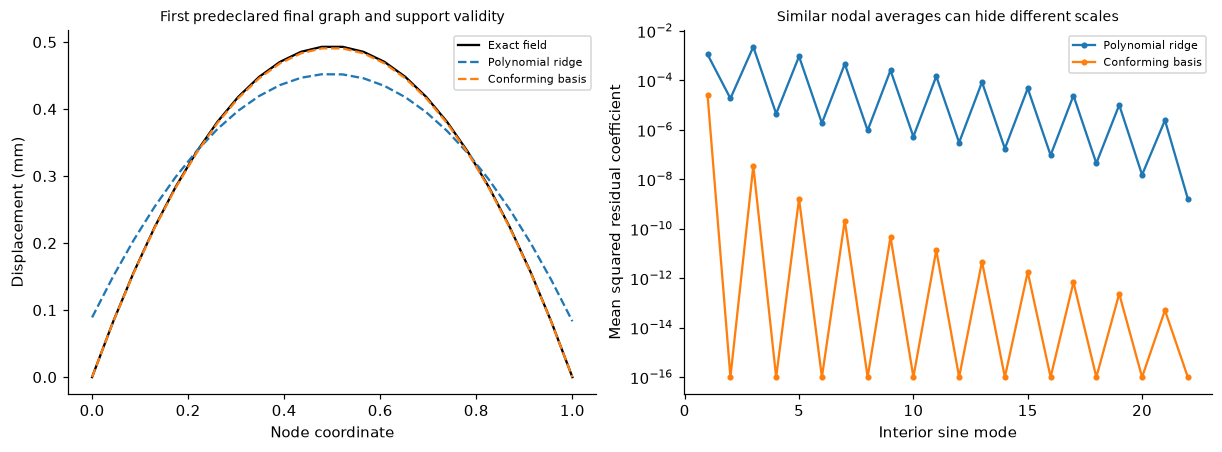

In [2]:
from sklearn.linear_model import Ridge
from scipy.fft import dst
x=np.linspace(0,1,24);h=x[1]-x[0];qs=rng.uniform(.5,2,80);qf=rng.uniform(.5,2,40)
def features(q):
    Q=np.repeat(q,24);xx=np.tile(x,len(q));return np.c_[Q,xx,xx**2,Q*xx,Q*xx**2]
us=qs[:,None]*x*(1-x);uf=qf[:,None]*x*(1-x);mask=np.tile((x>0)&(x<1),80);noisy=us+rng.normal(scale=.03,size=us.shape);ridge=Ridge(alpha=2).fit(features(qs)[mask],noisy.ravel()[mask]);basis=us[:,1:-1].ravel();coefficient=float(basis@noisy[:,1:-1].ravel()/(basis@basis));fields={'Polynomial ridge':ridge.predict(features(qf)).reshape(40,24),'Conforming basis':coefficient*uf};field_rows={};spectra={}
for name,u in fields.items():
    error=u-uf;edge=np.diff(error,axis=1)/h;equation=-np.diff(u,n=2,axis=1)/h**2-2*qf[:,None];spectrum=np.mean(dst(error[:,1:-1],type=1,norm='ortho')**2,axis=0);spectra[name]=spectrum
    field_rows[name]={'node_RMSE_mm':float(np.sqrt(np.mean(error**2))),'edge_gradient_RMSE_mm_per_length':float(np.sqrt(np.mean(edge**2))),'graph_peak_MAE_mm':float(np.mean(abs(u.max(1)-uf.max(1)))),'mean_field_L2_mm':float(np.mean(np.sqrt(np.trapezoid(error**2,x=x,axis=1)))),'maximum_boundary_mm':float(np.max(abs(u[:,[0,-1]]))),'equation_residual_RMS':float(np.sqrt(np.mean(equation**2))),'high_mode_residual_energy':float(spectrum[11:].sum())};assert np.isclose(np.sum(dst(error[:,1:-1],type=1,norm='ortho')**2),np.sum(error[:,1:-1]**2))
assert np.allclose(fields['Conforming basis'][:,[0,-1]],0);assert np.allclose(-np.diff(uf,n=2,axis=1)/h**2,2*qf[:,None]);RESULTS.update(source_graphs=80,final_graphs=40,nodes_per_graph=24,spatial_step=float(h),conforming_fit_coefficient=coefficient,field_scores=field_rows,residual_sine_spectra={k:v.tolist() for k,v in spectra.items()});display(pd.DataFrame(field_rows).T);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].plot(x,uf[0],color='black',label='Exact field')
for name,u in fields.items():axes[0].plot(x,u[0],'--',label=name);axes[1].semilogy(np.arange(1,23),spectra[name]+1e-16,'o-',markersize=3,label=name)
axes[0].set(xlabel='Node coordinate',ylabel='Displacement (mm)',title='First predeclared final graph and support validity');axes[0].legend(fontsize=7);axes[1].set(xlabel='Interior sine mode',ylabel='Mean squared residual coefficient',title='Similar nodal averages can hide different scales');axes[1].legend(fontsize=7);plt.show()


<a id="horizon-and-graph-aggregation"></a>
 ## Evaluate repeated forecast origins within their parent trajectory
 Independently generate 100 trajectories of length 100 from a stable autoregression with a known sinusoidal external load and independent disturbances. Fit a one-step ridge model on the first 60 whole trajectories. For each of the remaining 40, launch forecasts from fixed origins 20,30,40,50,60,70 at horizons 1,3,6,12, recursively feeding predictions back and supplying the known future external load. Compare persistence on identical targets. Average absolute error within each trajectory before averaging trajectories; overlapping horizons are not independent replicates. This experiment observes supplied load schedules, not unknown future covariates. Pair horizon errors with graph equation/boundary summaries rather than collapsing them into a mixed-unit total.


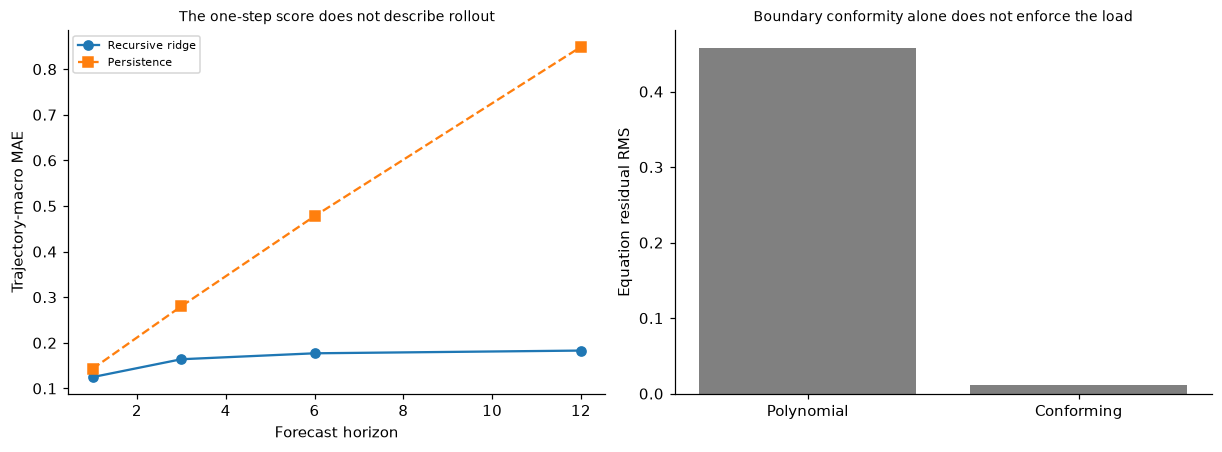

In [3]:
length=100;trajectories=100;tt=np.arange(length);forcing=.2*np.sin(tt/6);series=np.zeros((trajectories,length));series[:,0]=rng.normal(size=trajectories)
for t in range(1,length):series[:,t]=.75*series[:,t-1]+forcing[t]+rng.normal(scale=.15,size=trajectories)
ftrain=np.c_[series[:60,:-1].ravel(),np.tile(forcing[1:],60)];target=series[:60,1:].ravel();forecast=Ridge(alpha=.1).fit(ftrain,target);horizons=[1,3,6,12];origins=[20,30,40,50,60,70];hrows={}
for horizon in horizons:
    fitted=[];persist=[]
    for a in range(60,100):
        er=[];ep=[]
        for origin in origins:
            z=float(series[a,origin])
            for step in range(1,horizon+1):z=float(forecast.predict([[z,forcing[origin+step]]])[0])
            er.append(abs(z-series[a,origin+horizon]));ep.append(abs(series[a,origin]-series[a,origin+horizon]))
        fitted.append(float(np.mean(er)));persist.append(float(np.mean(ep)))
    hrows[str(horizon)]={'recursive_MAE':float(np.mean(fitted)),'persistence_MAE':float(np.mean(persist)),'trajectory_MAE_recursive':fitted,'trajectory_MAE_persistence':persist};assert len(fitted)==40
assert max(origins)+max(horizons)<length;assert len(target)==60*99;RESULTS.update(forecast_source_trajectories=60,forecast_final_trajectories=40,fixed_origins=origins,known_future_forcing=True,horizon_scores=hrows);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].plot(horizons,[hrows[str(k)]['recursive_MAE'] for k in horizons],'o-',label='Recursive ridge');axes[0].plot(horizons,[hrows[str(k)]['persistence_MAE'] for k in horizons],'s--',label='Persistence');axes[0].set(xlabel='Forecast horizon',ylabel='Trajectory-macro MAE',title='The one-step score does not describe rollout');axes[0].legend(fontsize=7);names=list(field_rows);xx=np.arange(2);axes[1].bar(xx,[field_rows[k]['equation_residual_RMS'] for k in names],color='.5');axes[1].set(xticks=xx,xticklabels=['Polynomial','Conforming'],ylabel='Equation residual RMS',title='Boundary conformity alone does not enforce the load');plt.show()


In [4]:
summary={'example_id':'code_191','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual unconstrained and boundary-conforming field surrogates', 'node edge graph L2 gradient boundary and equation residual assessment', 'discrete sine residual spectrum and whole-graph aggregation', 'actual source-fitted recursive forecasts assessed by horizon and trajectory'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual unconstrained and boundary-conforming field surrogates", "node edge graph L2 gradient boundary and equation residual assessment", "discrete sine residual spectrum and whole-graph aggregation", "actual source-fitted recursive forecasts assessed by horizon and trajectory"], "elapsed_seconds": 0.523, "example_id": "code_191", "hardware": "Darwin arm64 CPU", "results": {"conforming_fit_coefficient": 0.9953376931341757, "field_scores": {"Conforming basis": {"edge_gradient_RMSE_mm_per_length": 0.0033153153060238878, "equation_residual_RMS": 0.011495459519613371, "graph_peak_MAE_mm": 0.0013691158857595802, "high_mode_residual_energy": 7.44100009538507e-12, "maximum_boundary_mm": 0.0, "mean_field_L2_mm": 0.001001752758655316, "node_RMSE_mm": 0.001027290411690323}, "Polynomial ridge": {"edge_gradient_RMSE_mm_per_length": 0.1322090762005002, "equation_residual_RMS": 0.45820769850570087, "graph_peak_MAE_mm": 0.014891686685808193, "high_mod